In [ ]:
pip install numpy pandas scikit-learn openpyxl imbalanced-learn

In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

Accuracy: 0.9615674453654861
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       1.00      1.00      1.00       475
           2       1.00      1.00      1.00       346
           3       1.00      1.00      1.00       345
           4       1.00      1.00      1.00       323
           5       1.00      0.99      1.00       352
           6       0.99      1.00      1.00       329
           7       1.00      1.00      1.00       313
           8       1.00      1.00      1.00       344
           9       0.98      1.00      0.99       355
          10       0.98      0.98      0.98       368
          11       0.68      0.97      0.80       288
          12       0.00      0.00      0.00       130
          13       0.00      0.00      0.00         1

    accuracy                           0.96      3981
   macro avg       0.83      0.85      0.84      3981
weighted avg       0.94     

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classif

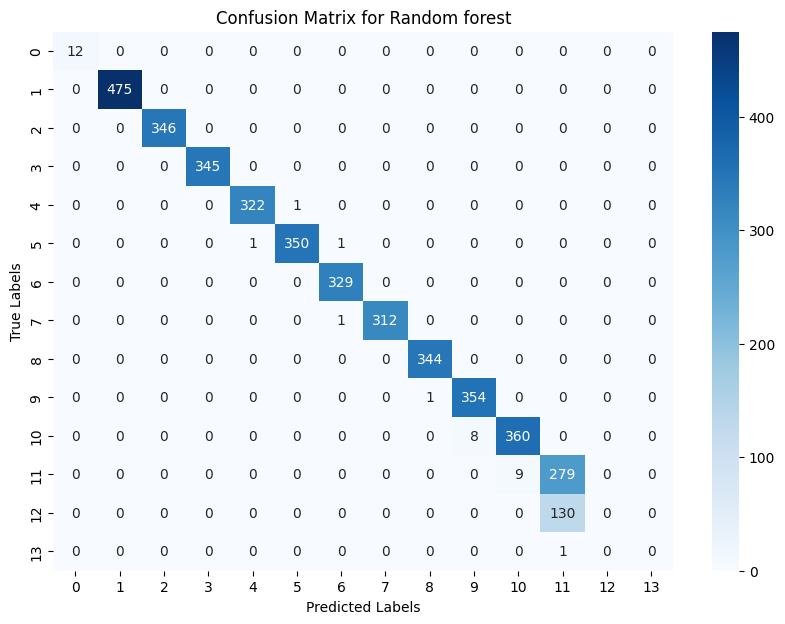

<ipython-input-4-35b3c2d1ebd0>:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=metrics.index, y=metrics['precision'], palette='viridis')


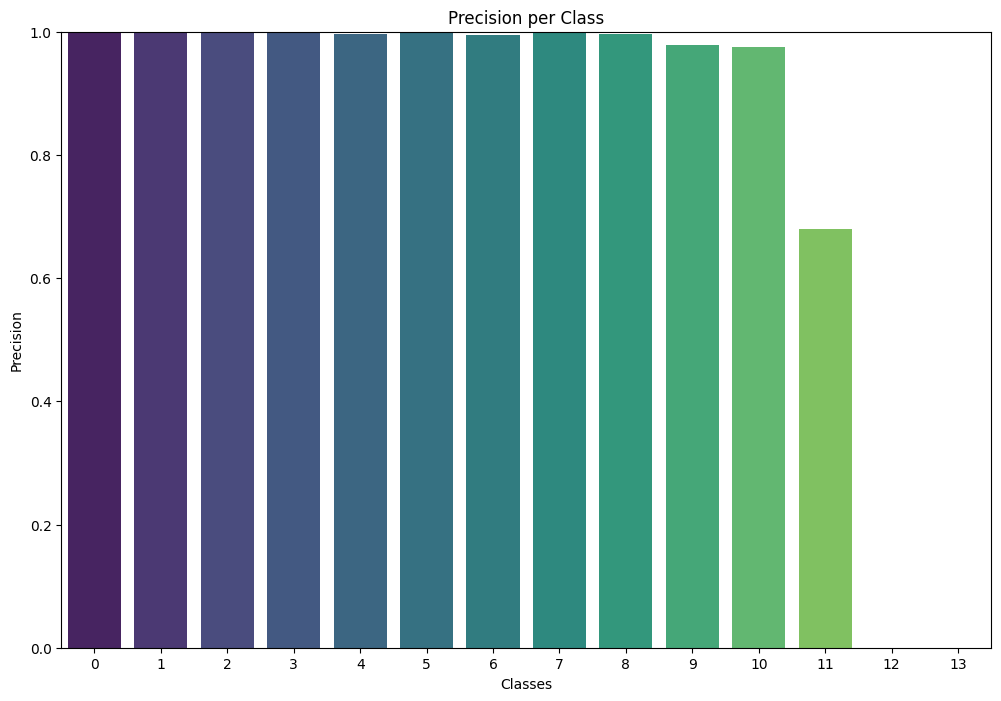

<ipython-input-4-35b3c2d1ebd0>:68: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=metrics.index, y=metrics['recall'], palette='viridis')


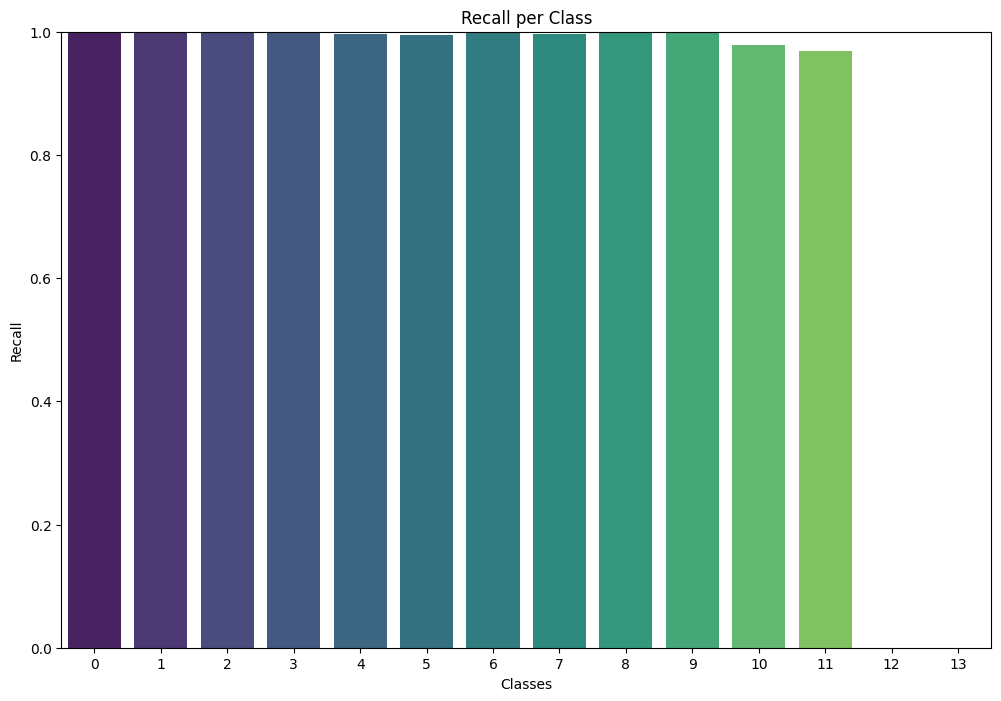

<ipython-input-4-35b3c2d1ebd0>:77: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=metrics.index, y=metrics['f1-score'], palette='viridis')


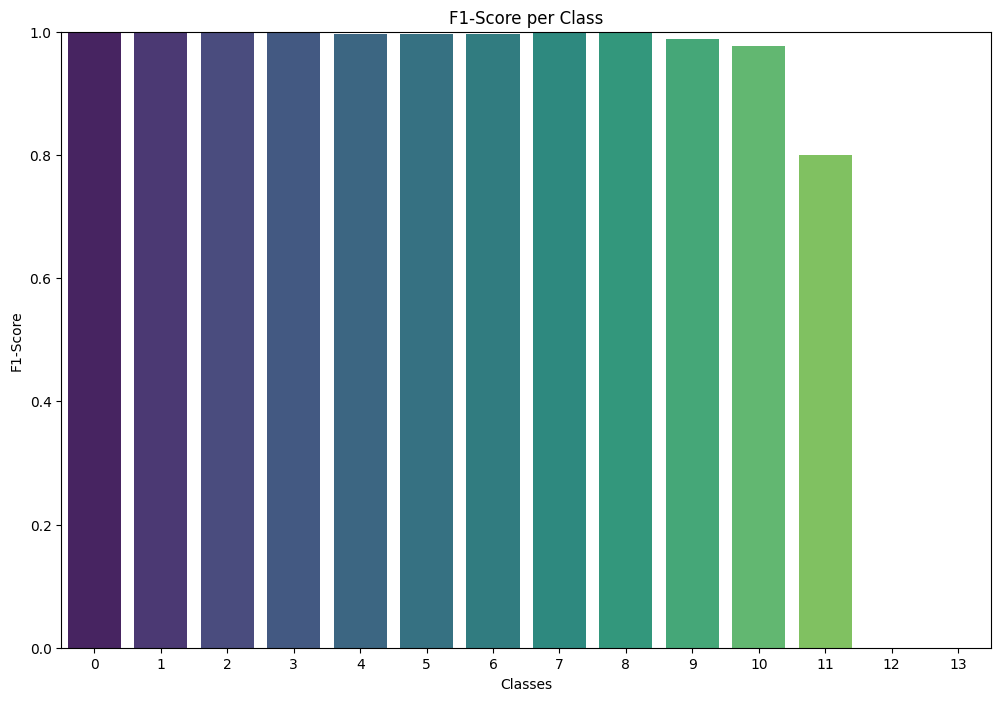

In [ ]:
# Load your dataset from a CSV file
data = pd.read_csv('/content/preprocessed_pqd_data.csv')

# Check for missing values
if data.isnull().sum().any():
    data = data.dropna()  # Remove rows with missing values or use imputation

# Split the data into features and labels
X = data.iloc[:, :-1].values  # Assuming all columns except the last are features
y = data.iloc[:, -1].values  # Assuming the last column is the label

# Ensure labels are categorical (convert to integers if necessary)
if y.dtype.kind in 'fc':  # Check if labels are float or continuous
    y = y.astype(int)

# Example
le = LabelEncoder()
y_encoded = le.fit_transform(y)


# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.1, random_state=42)

# Initialize the RandomForestClassifier with default parameters
rf_classifier = RandomForestClassifier(random_state=42, max_depth=5, min_samples_split=5, min_samples_leaf=6)

# Train the RandomForestClassifier
rf_classifier.fit(X_train, y_train)

# Make predictions on the test set
y_pred = rf_classifier.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)
print("Classification Report:")
report = classification_report(y_test, y_pred, output_dict=True)
print(classification_report(y_test, y_pred))

# Confusion Matrix
conf_matrix = confusion_matrix(y_test, y_pred)

# Plotting the Confusion Matrix
plt.figure(figsize=(10, 7))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title(f'Confusion Matrix for Random forest')
plt.show()

# Convert classification report to DataFrame
report_df = pd.DataFrame(report).transpose()

# Extract precision, recall, and f1-score
metrics = report_df[['precision', 'recall', 'f1-score']].iloc[:-3]  # Exclude support and average metrics

# Plot precision
plt.figure(figsize=(12, 8))
sns.barplot(x=metrics.index, y=metrics['precision'], palette='viridis')
plt.title('Precision per Class')
plt.xlabel('Classes')
plt.ylabel('Precision')
plt.ylim(0, 1)
plt.show()

# Plot recall
plt.figure(figsize=(12, 8))
sns.barplot(x=metrics.index, y=metrics['recall'], palette='viridis')
plt.title('Recall per Class')
plt.xlabel('Classes')
plt.ylabel('Recall')
plt.ylim(0, 1)
plt.show()

# Plot f1-score
plt.figure(figsize=(12, 8))
sns.barplot(x=metrics.index, y=metrics['f1-score'], palette='viridis')
plt.title('F1-Score per Class')
plt.xlabel('Classes')
plt.ylabel('F1-Score')
plt.ylim(0, 1)
plt.show()

Accuracy: 0.9911946692051404
Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.80      0.89       115
           1       0.99      0.99      0.99      4128
           2       0.99      0.99      0.99      3299
           3       0.99      1.00      0.99      3294
           4       1.00      0.99      0.99      3286
           5       0.99      0.99      0.99      3302
           6       0.99      1.00      1.00      3288
           7       0.98      1.00      0.99      3271
           8       1.00      0.98      0.99      3305
           9       1.00      1.00      1.00      3278
          10       0.98      0.99      0.99      3294
          11       0.99      0.98      0.98      2638
          12       0.99      0.99      0.99      1277
          13       1.00      0.81      0.90        43

    accuracy                           0.99     37818
   macro avg       0.99      0.97      0.98     37818
weighted avg       0.99     

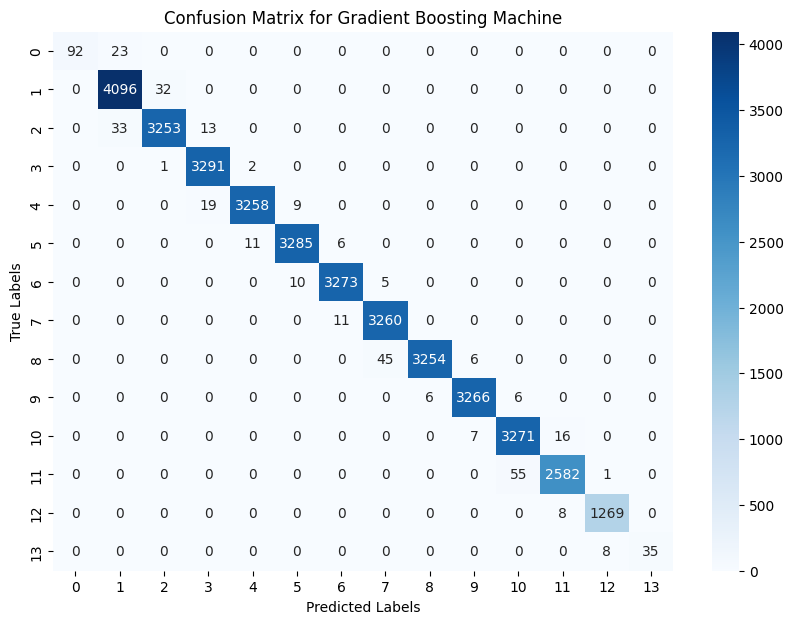

<ipython-input-8-a7dcf1d77011>:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=metrics.index, y=metrics['precision'], palette='viridis')


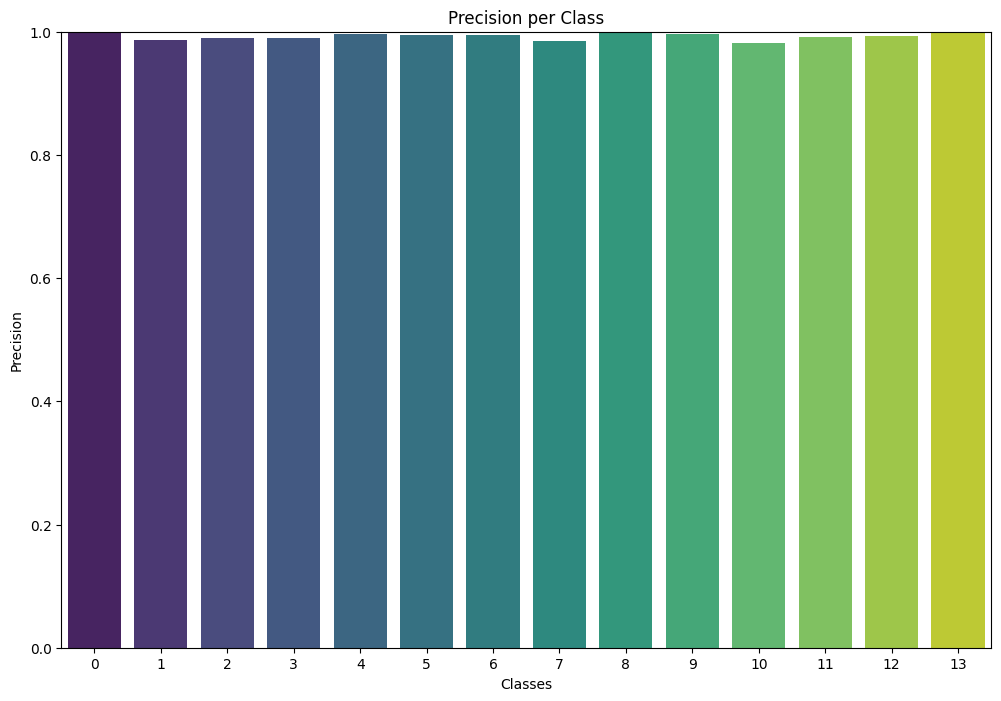

<ipython-input-8-a7dcf1d77011>:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=metrics.index, y=metrics['recall'], palette='viridis')


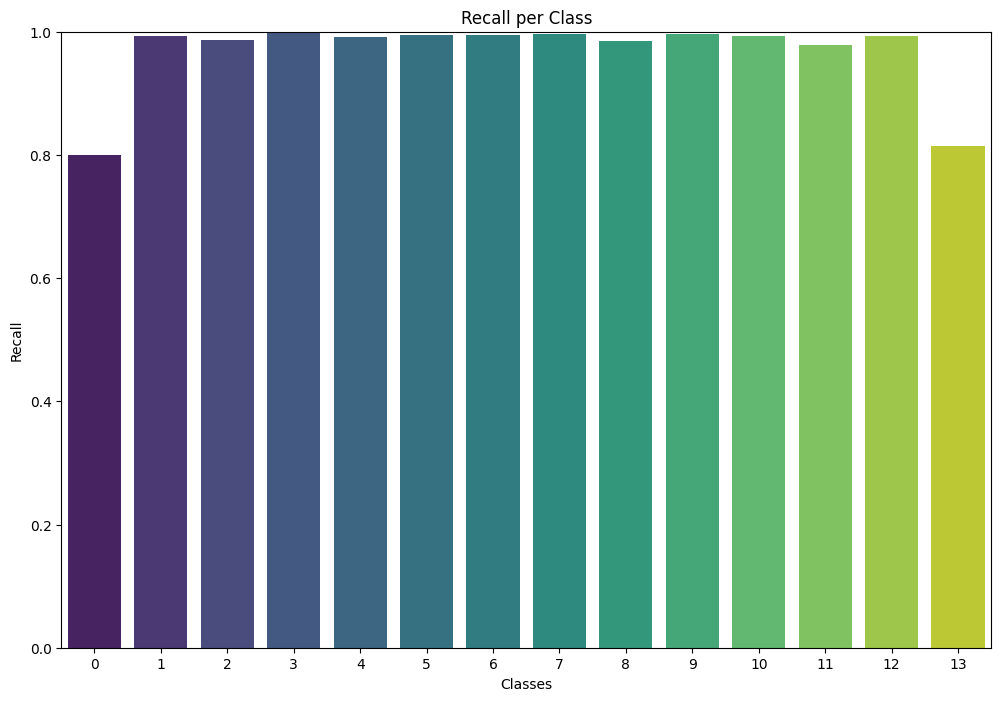

<ipython-input-8-a7dcf1d77011>:56: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=metrics.index, y=metrics['f1-score'], palette='viridis')


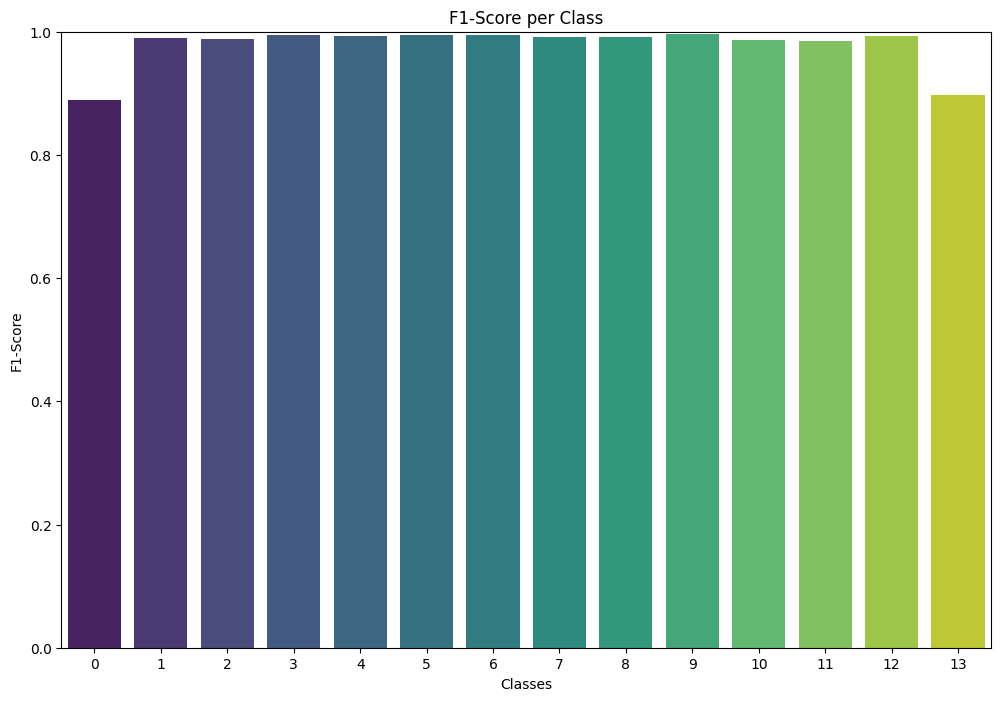

In [ ]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.95, random_state=42)

# Initialize the Gradient Boosting classifier
gb_classifier = GradientBoostingClassifier(n_estimators=100, learning_rate=0.05, random_state=42)

# Train the classifier
gb_classifier.fit(X_train, y_train)

# Predict the test set results
y_pred = gb_classifier.predict(X_test)

# Evaluate the classifier
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:")
report = classification_report(y_test, y_pred, output_dict=True)
print(classification_report(y_test, y_pred))

# Confusion Matrix
conf_matrix = confusion_matrix(y_test, y_pred)

# Plotting the Confusion Matrix
plt.figure(figsize=(10, 7))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title(f'Confusion Matrix for Gradient Boosting Machine')
plt.show()

# Convert classification report to DataFrame
report_df = pd.DataFrame(report).transpose()

# Extract precision, recall, and f1-score
metrics = report_df[['precision', 'recall', 'f1-score']].iloc[:-3]  # Exclude support and average metrics

# Plot precision
plt.figure(figsize=(12, 8))
sns.barplot(x=metrics.index, y=metrics['precision'], palette='viridis')
plt.title('Precision per Class')
plt.xlabel('Classes')
plt.ylabel('Precision')
plt.ylim(0, 1)
plt.show()

# Plot recall
plt.figure(figsize=(12, 8))
sns.barplot(x=metrics.index, y=metrics['recall'], palette='viridis')
plt.title('Recall per Class')
plt.xlabel('Classes')
plt.ylabel('Recall')
plt.ylim(0, 1)
plt.show()

# Plot f1-score
plt.figure(figsize=(12, 8))
sns.barplot(x=metrics.index, y=metrics['f1-score'], palette='viridis')
plt.title('F1-Score per Class')
plt.xlabel('Classes')
plt.ylabel('F1-Score')
plt.ylim(0, 1)
plt.show()

Accuracy: 0.9130016223058136
Classification Report:
              precision    recall  f1-score   support

           0       0.86      1.00      0.92      4031
           1       1.00      0.67      0.80      4015
           2       0.85      0.99      0.92      3998
           3       0.99      0.98      0.99      3997
           4       0.98      1.00      0.99      4001
           5       0.97      0.96      0.96      4006
           6       0.97      0.94      0.95      4007
           7       0.94      1.00      0.97      3970
           8       0.99      0.93      0.96      4016
           9       0.91      0.99      0.95      3992
          10       0.99      0.93      0.96      4028
          11       0.87      0.93      0.90      4020
          12       0.88      0.47      0.62      3999
          13       0.71      1.00      0.83      4013

    accuracy                           0.91     56093
   macro avg       0.92      0.91      0.91     56093
weighted avg       0.92     

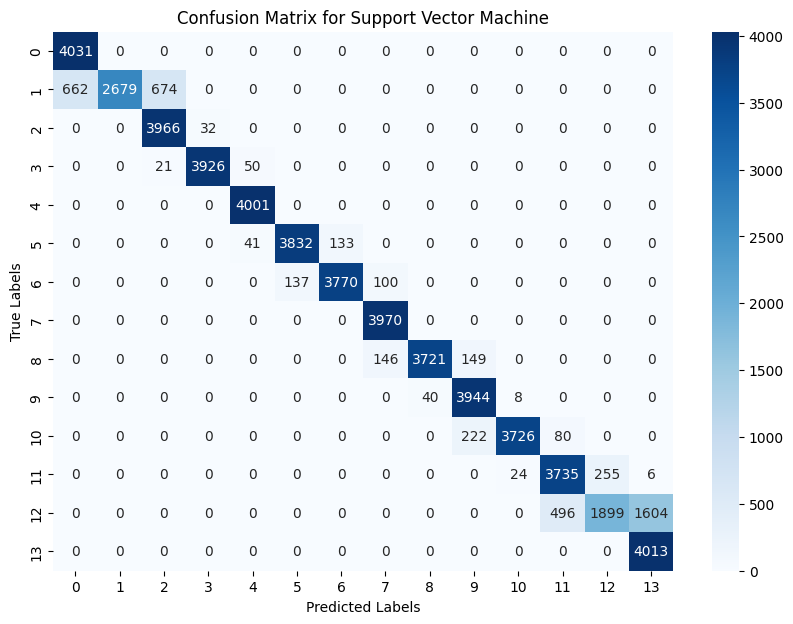

<ipython-input-29-4bc63bd2f545>:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=metrics.index, y=metrics['precision'], palette='viridis')


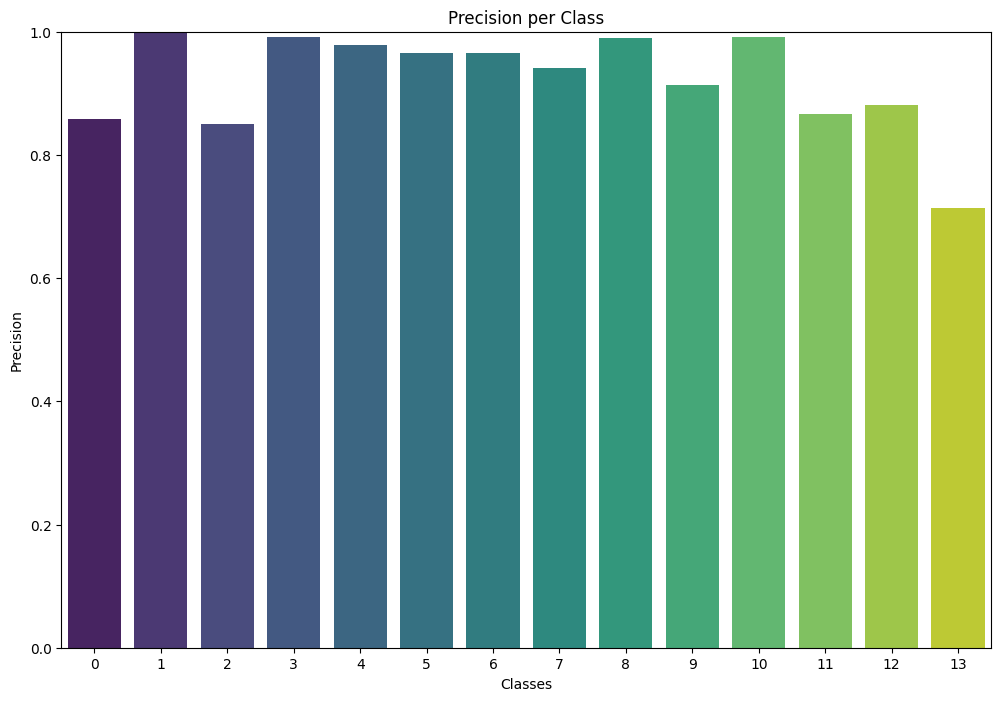

<ipython-input-29-4bc63bd2f545>:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=metrics.index, y=metrics['recall'], palette='viridis')


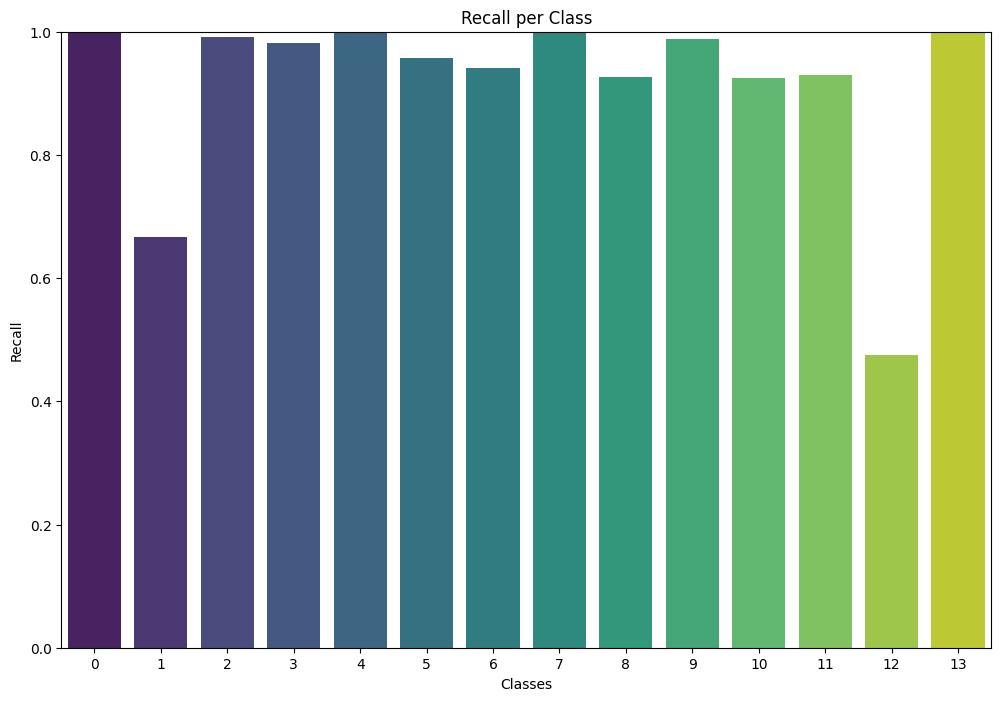

<ipython-input-29-4bc63bd2f545>:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=metrics.index, y=metrics['f1-score'], palette='viridis')


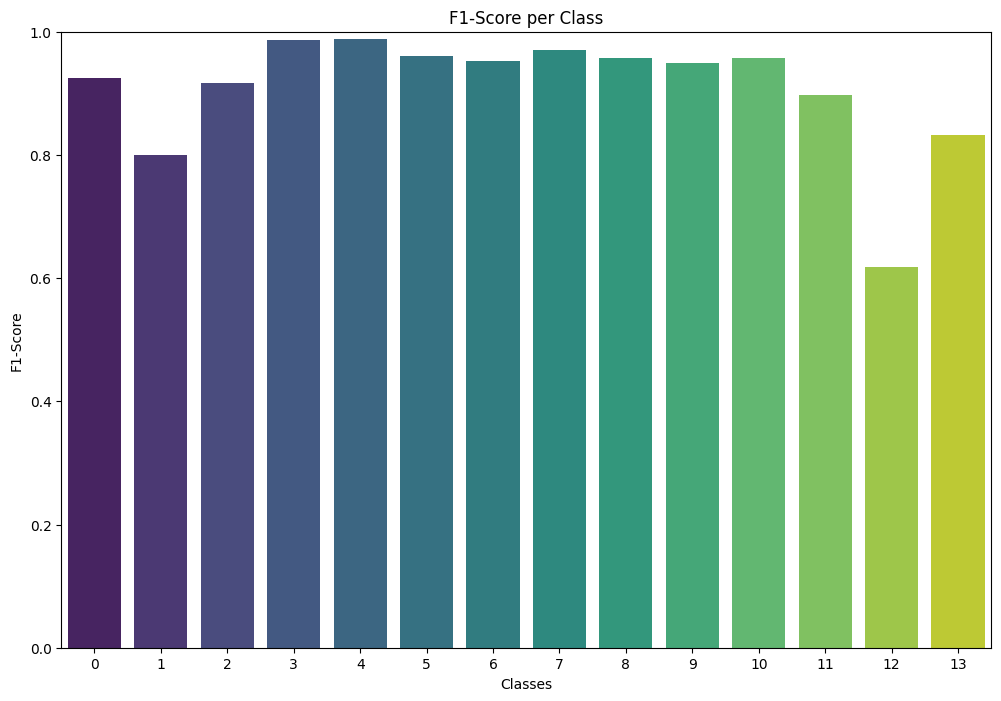

In [ ]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y_encoded, test_size=0.92, random_state=42)

# Initialize the SVM classifier
svm_classifier = SVC(kernel='rbf', C=0.05,gamma='scale', random_state=35)

# Train the classifier
svm_classifier.fit(X_train, y_train)

# Predict the test set results
y_pred = svm_classifier.predict(X_test)

# Evaluate the classifier
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:")
target_names = [str(i) for i in range(14)]
report = classification_report(y_test, y_pred, target_names=target_names, output_dict=True)
print(classification_report(y_test, y_pred, target_names=target_names))

# Confusion Matrix
conf_matrix = confusion_matrix(y_test, y_pred)

# Plotting the Confusion Matrix
plt.figure(figsize=(10, 7))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title(f'Confusion Matrix for Support Vector Machine')
plt.show()

# Convert classification report to DataFrame
report_df = pd.DataFrame(report).transpose()

# Extract precision, recall, and f1-score
metrics = report_df[['precision', 'recall', 'f1-score']].iloc[:-3]  # Exclude support and average metrics

# Plot precision
plt.figure(figsize=(12, 8))
sns.barplot(x=metrics.index, y=metrics['precision'], palette='viridis')
plt.title('Precision per Class')
plt.xlabel('Classes')
plt.ylabel('Precision')
plt.ylim(0, 1)
plt.show()

# Plot recall
plt.figure(figsize=(12, 8))
sns.barplot(x=metrics.index, y=metrics['recall'], palette='viridis')
plt.title('Recall per Class')
plt.xlabel('Classes')
plt.ylabel('Recall')
plt.ylim(0, 1)
plt.show()

# Plot f1-score
plt.figure(figsize=(12, 8))
sns.barplot(x=metrics.index, y=metrics['f1-score'], palette='viridis')
plt.title('F1-Score per Class')
plt.xlabel('Classes')
plt.ylabel('F1-Score')
plt.ylim(0, 1)
plt.show()

Accuracy: 0.9035376099356542
Classification Report:


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classif

              precision    recall  f1-score   support

           0       0.00      0.00      0.00       108
           1       0.88      1.00      0.94      3907
           2       0.94      0.87      0.90      3108
           3       0.97      0.94      0.96      3095
           4       0.92      0.97      0.95      3086
           5       1.00      0.84      0.91      3100
           6       0.90      0.99      0.94      3077
           7       0.93      0.97      0.95      3077
           8       1.00      0.80      0.89      3108
           9       0.83      1.00      0.91      3075
          10       0.83      0.89      0.86      3120
          11       0.79      0.72      0.76      2492
          12       0.84      0.73      0.78      1199
          13       0.00      0.00      0.00        37

    accuracy                           0.90     35589
   macro avg       0.77      0.77      0.77     35589
weighted avg       0.90      0.90      0.90     35589



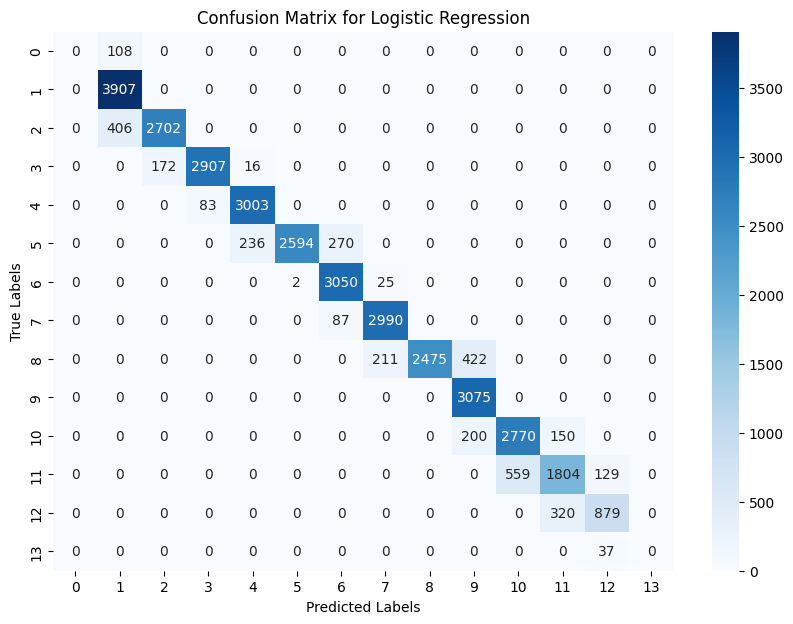

<ipython-input-6-d4443f63b735>:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=metrics.index, y=metrics['precision'], palette='viridis')


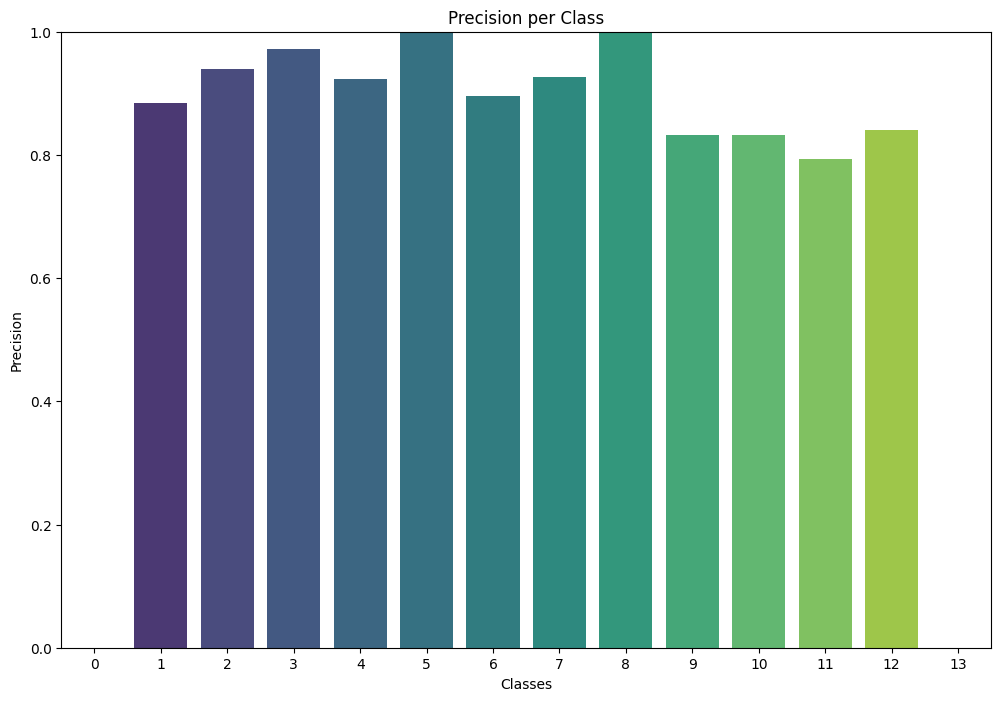

<ipython-input-6-d4443f63b735>:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=metrics.index, y=metrics['recall'], palette='viridis')


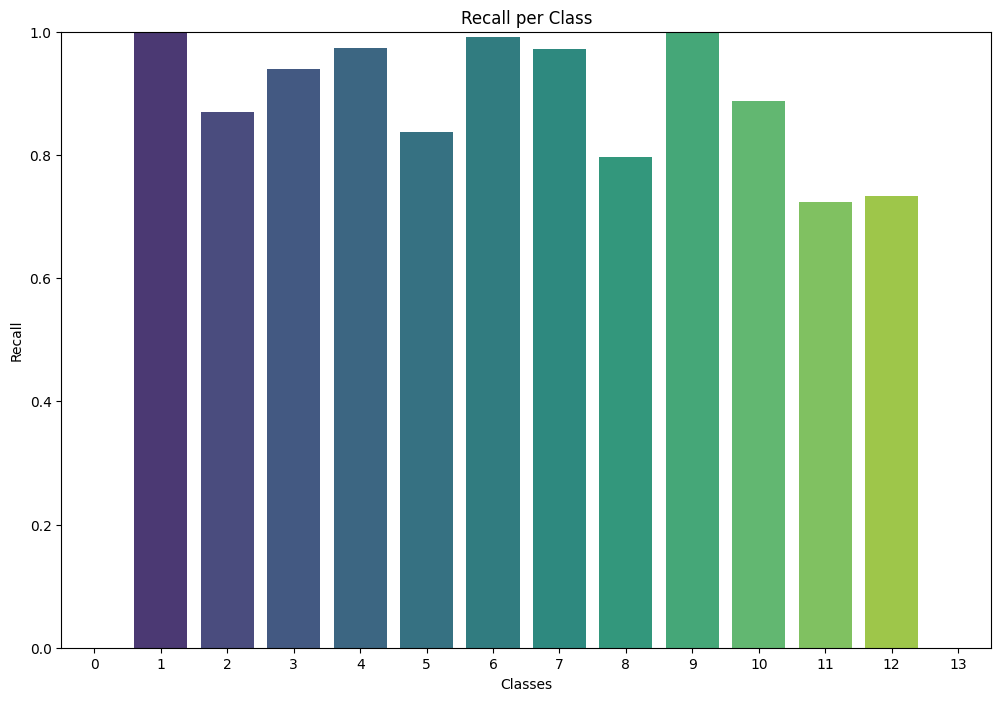

<ipython-input-6-d4443f63b735>:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=metrics.index, y=metrics['f1-score'], palette='viridis')


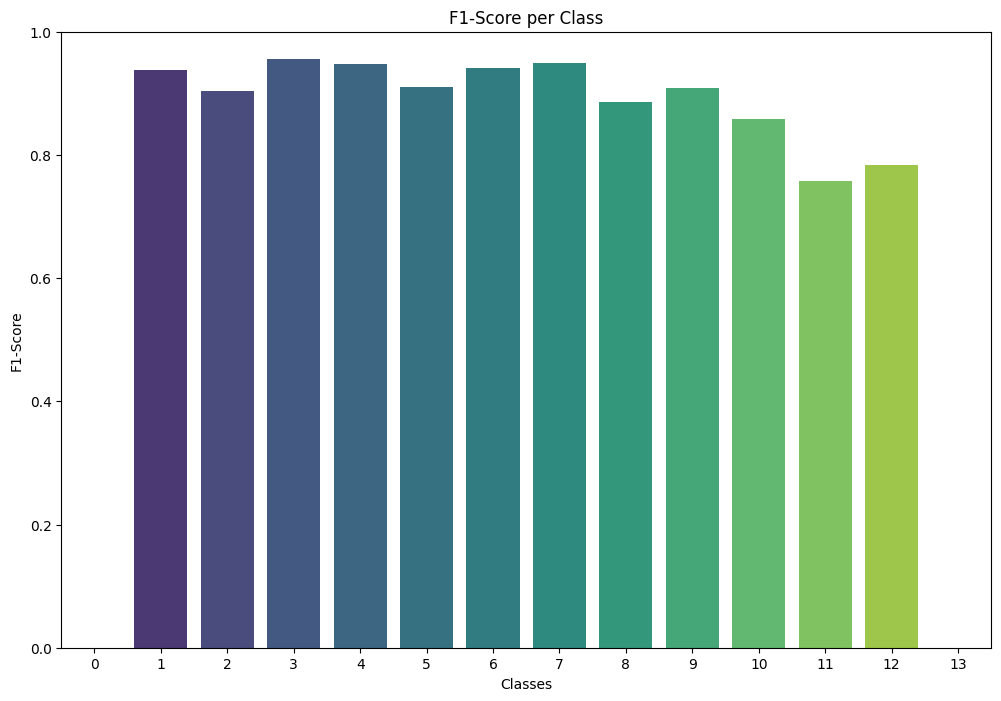

In [ ]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.894, random_state=42)

# Initialize the Logistic Regression classifier
log_reg_classifier = LogisticRegression(max_iter=1000, random_state=42)

# Train the classifier
log_reg_classifier.fit(X_train, y_train)

# Predict the test set results
y_pred = log_reg_classifier.predict(X_test)

# Evaluate the classifier
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:")
target_names = [str(i) for i in range(14)]
report = classification_report(y_test, y_pred, target_names=target_names, output_dict=True)
print(classification_report(y_test, y_pred, target_names=target_names))

# Confusion Matrix
conf_matrix = confusion_matrix(y_test, y_pred)

# Plotting the Confusion Matrix
plt.figure(figsize=(10, 7))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title(f'Confusion Matrix for Logistic Regression')
plt.show()

# Convert classification report to DataFrame
report_df = pd.DataFrame(report).transpose()

# Extract precision, recall, and f1-score
metrics = report_df[['precision', 'recall', 'f1-score']].iloc[:-3]  # Exclude support and average metrics

# Plot precision
plt.figure(figsize=(12, 8))
sns.barplot(x=metrics.index, y=metrics['precision'], palette='viridis')
plt.title('Precision per Class')
plt.xlabel('Classes')
plt.ylabel('Precision')
plt.ylim(0, 1)
plt.show()

# Plot recall
plt.figure(figsize=(12, 8))
sns.barplot(x=metrics.index, y=metrics['recall'], palette='viridis')
plt.title('Recall per Class')
plt.xlabel('Classes')
plt.ylabel('Recall')
plt.ylim(0, 1)
plt.show()

# Plot f1-score
plt.figure(figsize=(12, 8))
sns.barplot(x=metrics.index, y=metrics['f1-score'], palette='viridis')
plt.title('F1-Score per Class')
plt.xlabel('Classes')
plt.ylabel('F1-Score')
plt.ylim(0, 1)
plt.show()

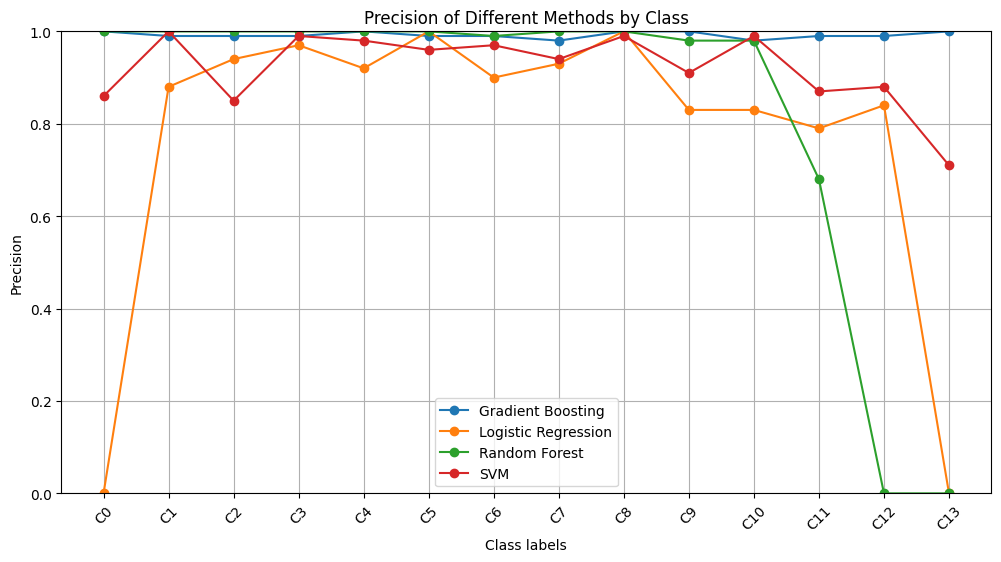

In [3]:
# Example precision values extracted from classification reports for the four methods
# Replace these with the actual precision values from your classification reports
precision_values = {
    "Gradient Boosting": [1.00, 0.99, 0.99, 0.99, 1.00, 0.99, 0.99, 0.98, 1.00, 1.00, 0.98, 0.99, 0.99, 1.00],
    "Logistic Regression": [0.00, 0.88, 0.94, 0.97, 0.92, 1.00, 0.90, 0.93, 1.00, 0.83, 0.83, 0.79, 0.84, 0.00],
    "Random Forest": [1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 0.99, 1.00, 1.00, 0.98, 0.98, 0.68, 0.00, 0.00],
    "SVM": [0.86, 1.00, 0.85, 0.99, 0.98, 0.96, 0.97, 0.94, 0.99, 0.91, 0.99, 0.87, 0.88, 0.71]
}

# Class labels (Replace these with the actual class labels from your classification reports)
classes = ['C0', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9', 'C10', 'C11', 'C12', 'C13']

# Create a DataFrame for easier plotting
df = pd.DataFrame(precision_values, index=classes)

# Plot the graph
plt.figure(figsize=(12, 6))

for method in df.columns:
    plt.plot(df.index, df[method], marker='o', label=method)

plt.xlabel('Class labels')
plt.ylabel('Precision')
plt.title('Precision of Different Methods by Class')
plt.legend()
plt.grid(True)
plt.ylim(0.00, 1.0)
plt.xticks(rotation=45)
plt.show()

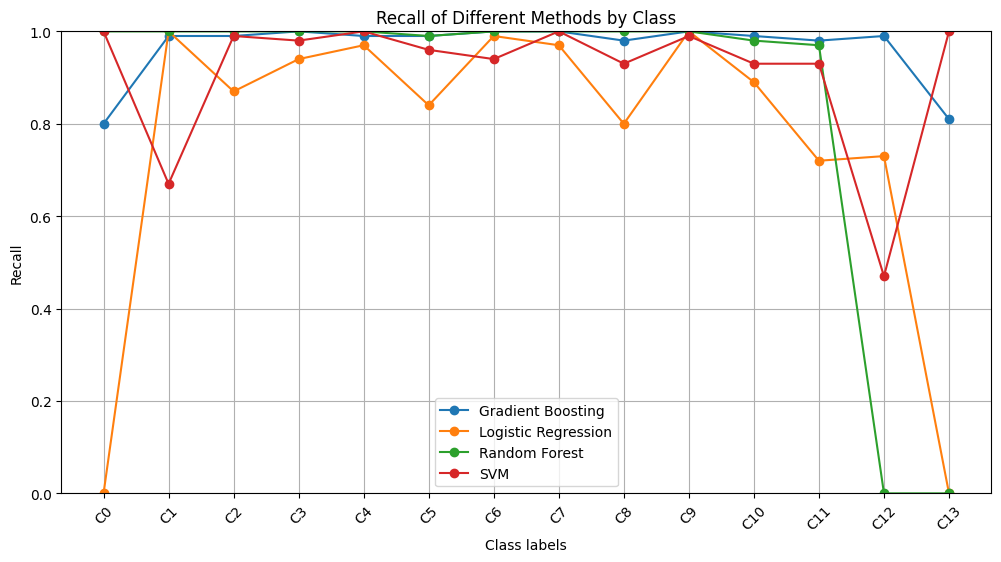

In [ ]:
# Example precision values extracted from classification reports for the four methods
# Replace these with the actual precision values from your classification reports
recall_values = {
    "Gradient Boosting": [0.80, 0.99, 0.99, 1.00, 0.99, 0.99, 1.00, 1.00, 0.98, 1.00, 0.99, 0.98, 0.99, 0.81],
    "Logistic Regression": [0.00, 1.00, 0.87, 0.94, 0.97, 0.84, 0.99, 0.97, 0.80, 1.00, 0.89, 0.72, 0.73, 0.00],
    "Random Forest": [1.00, 1.00, 1.00, 1.00, 1.00, 0.99, 1.00, 1.00, 1.00, 1.00, 0.98, 0.97, 0.00, 0.00],
    "SVM": [1.00, 0.67, 0.99, 0.98, 1.00, 0.96, 0.94, 1.00, 0.93, 0.99, 0.93, 0.93, 0.47, 1.00]
}

# Class labels (Replace these with the actual class labels from your classification reports)
classes = ['C0', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9', 'C10', 'C11', 'C12', 'C13']

# Create a DataFrame for easier plotting
df = pd.DataFrame(recall_values, index=classes)

# Plot the graph
plt.figure(figsize=(12, 6))

for method in df.columns:
    plt.plot(df.index, df[method], marker='o', label=method)

plt.xlabel('Class labels')
plt.ylabel('Recall')
plt.title('Recall of Different Methods by Class')
plt.legend()
plt.grid(True)
plt.ylim(0.00, 1.0)
plt.xticks(rotation=45)
plt.show()

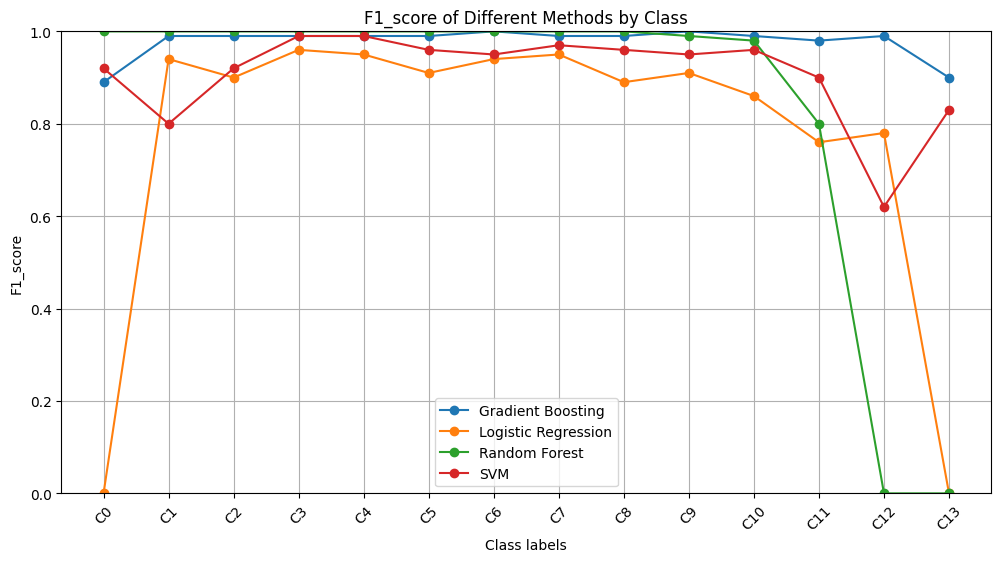

In [ ]:
# Example precision values extracted from classification reports for the four methods
# Replace these with the actual precision values from your classification reports
F1_score_values = {
    "Gradient Boosting": [0.89, 0.99, 0.99, 0.99, 0.99, 0.99, 1.00, 0.99, 0.99, 1.00, 0.99, 0.98, 0.99, 0.90],
    "Logistic Regression": [0.00, 0.94, 0.90, 0.96, 0.95, 0.91, 0.94, 0.95, 0.89, 0.91, 0.86, 0.76, 0.78, 0.00],
    "Random Forest": [1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 0.99, 0.98, 0.80, 0.00, 0.00],
    "SVM": [0.92, 0.80, 0.92, 0.99, 0.99, 0.96, 0.95, 0.97, 0.96, 0.95, 0.96, 0.90, 0.62, 0.83]
}

# Class labels (Replace these with the actual class labels from your classification reports)
classes = ['C0', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9', 'C10', 'C11', 'C12', 'C13']

# Create a DataFrame for easier plotting
df = pd.DataFrame(F1_score_values, index=classes)

# Plot the graph
plt.figure(figsize=(12, 6))

for method in df.columns:
    plt.plot(df.index, df[method], marker='o', label=method)

plt.xlabel('Class labels')
plt.ylabel('F1_score')
plt.title('F1_score of Different Methods by Class')
plt.legend()
plt.grid(True)
plt.ylim(0.00, 1.0)
plt.xticks(rotation=45)
plt.show()